# 09 — Experimentos v2: base ampliada, prueba independiente y mejoras justificadas

**Fase CRISP-DM:** modelado y evaluación (iteración 2).

Este cuaderno responde a tres preguntas:

1. ¿Cuánto mejoran los modelos con el lote revisado del 26/11 (41 imágenes nuevas)?
2. ¿Qué cambios de modelo mejoran el **recall** y el **F1** de intermedia y mala?
3. ¿Cómo se comporta el modelo elegido en una **prueba independiente** que no participó en ninguna decisión?

Todas las decisiones de método y su justificación están en `docs/ajuste_y_cnn.md`
(D1–D13) y en `experiments/results/experimentos_v2/decisiones.json`. Las cifras del
texto se calculan a partir de los resultados; no se escriben a mano.

In [1]:
from pathlib import Path
import json, os, sys

candidatos = [Path.cwd(), *Path.cwd().parents]
PROYECTO = next(p for p in candidatos if (p / 'config/alcance_actual.json').is_file() and (p / 'src').is_dir())
sys.path.insert(0, str(PROYECTO))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
from src.data.base import cargar_base
from src.models.experimentos_base_ampliada import DECISIONES, ejecutar, escribir_manifiesto

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
SALIDA = PROYECTO / 'experiments/results/experimentos_v2'
base, columnas, estado = cargar_base(PROYECTO)
print('Base:', len(base), 'imágenes |', len(columnas), 'características |', base.grupo_particion.nunique(), 'grupos')
display(pd.crosstab([base.fuente], base.calidad_revisada, margins=True))

Base: 332 imágenes | 43 características | 31 grupos


calidad_revisada,buena,intermedia,mala,All
fuente,,,,
propia,15,2,8,25
propia_lote_20261126,8,19,14,41
publica,178,67,0,245
publica_kaggle,8,6,7,21
All,209,94,29,332


## 1. Decisiones de método

La tabla resume cada decisión y su justificación. La partición de prueba se fija con
una regla que usa solo etiquetas y grupos, **antes** de entrenar.

In [2]:
display(pd.DataFrame([{'decision': k, 'justificacion': v} for k, v in DECISIONES.items()]).style.set_properties(**{'text-align': 'left', 'white-space': 'pre-wrap'}))

,decision,justificacion
0,particion_prueba,"Se prueban StratifiedGroupKFold con 4, 5 y 6 bloques (semilla 42) y se elige como prueba el bloque que (a) contiene las tres calidades, (b) no incluye ninguna campaña con más del 10 % de la base y (c) tiene más grupos independientes; desempate por distribución de clases más cercana a la global. Por qué: con grupos, la unidad independiente es el grupo, no la foto. Una campaña de 70-103 fotos en prueba mediría un solo grupo y retiraría del entrenamiento casi toda una combinación fruta-calidad. La regla usa solo etiquetas y grupos; se fija antes de entrenar y no depende de ningún resultado."
1,validacion_desarrollo,StratifiedGroupKFold de 5 bloques sobre desarrollo con búsqueda interna agrupada (hasta 3 bloques). Por qué: los grupos impiden que vistas del mismo fruto o campaña queden a ambos lados; la anidación evita elegir hiperparámetros con los mismos datos que se usan para estimar el desempeño.
2,metrica_seleccion,"F1 macro de las predicciones externas de desarrollo; desempate por recall macro. Por qué: con 63 % de buenas, la exactitud premia predecir la mayoritaria; F1 macro da el mismo peso a buena, intermedia y mala y penaliza tanto falsos negativos (recall) como falsas alarmas."
3,balanceo,"Pesos de clase inversamente proporcionales a la frecuencia (class_weight=""balanced"" o pesos en la entropía cruzada) en lugar de sobremuestreo. Por qué: duplicar o sintetizar imágenes de pocas campañas no aporta variabilidad independiente y, con grupos, el sobremuestreo puede inflar la validación."
4,ajuste_decision,"Variante ""+umbral"": se multiplican las probabilidades por pesos (1, a, b) elegidos en las predicciones internas del entrenamiento para maximizar F1 macro; a, b en una rejilla logarítmica de 0,25 a 8. Por qué: es la regla de Bayes con costes por clase; corrige el sesgo hacia la clase mayoritaria y actúa directamente sobre el recall de intermedia y mala. Se ajusta solo con datos de entrenamiento."
5,caracteristicas_cnn,MobileNetV3 Small preentrenada en ImageNet y congelada produce 576 rasgos por imagen. Por qué: con ~300 imágenes no es viable aprender filtros profundos; la red congelada no ve etiquetas (sin fuga) y aporta texturas y bordes que las 43 características manuales no capturan.
6,modelo_profundo,"Cabezal propio (lineal o MLP de 64 unidades) sobre la red congelada, entrenado con AdamW, pesos de clase y aumentos (espejo, giros de 10 grados, brillo) solo en entrenamiento. Cumple el requisito de transferencia con capas congeladas y capas propias."
7,modelos_nuevos,"Regresión logística: referencia lineal regularizada, estable con pocos datos y probabilidades útiles para el ajuste de decisión. HistGradientBoosting: interacciones no lineales entre color y textura con regularización L2; sin parada temprana aleatoria para no partir grupos al azar. Fusión: concatena rasgos manuales (forma y color dentro de la máscara) y rasgos CNN (textura global)."
8,comparacion_antes_despues,"Las cifras del informe anterior usaban otro protocolo (3 bloques sobre 291 imágenes) y no son comparables. La comparación válida reentrena las configuraciones anteriores con este protocolo en las condiciones ""anterior"" y ""ampliada"" y las evalúa en las mismas filas."
9,pesos_fruta_calidad,"Variante ""_pesos_fruta"": cada imagen pesa N / (C·n_celda), donde n_celda es el número de imágenes de su combinación fruta-calidad en el entrenamiento y C el número de combinaciones presentes. Por qué: el diagnóstico mostró que la CNN aprendió la fruta como atajo (77 de 101 bananos son intermedios; casi todos los limones y manzanas, buenos). Con pesos por clase el modelo aún gana prediciendo ""banano = intermedia""; con pesos por combinación, cada celda fruta-calidad pesa igual y ese atajo deja de rendir."


## 2. Ejecución

Por defecto se reentrena todo (unos 8 minutos en CPU). Con `FRUTAS_USAR_RESULTADOS=1` se
reutilizan los resultados guardados si su huella coincide con la base actual.

In [3]:
reusar = os.environ.get('FRUTAS_USAR_RESULTADOS') == '1' and (SALIDA / 'decisiones.json').is_file()
if reusar:
    guardado = json.loads((SALIDA / 'decisiones.json').read_text(encoding='utf-8'))
    assert guardado['sha_base'] == estado['sha_base'], 'Los resultados no corresponden a la base actual.'
    print('Resultados guardados verificados contra la huella de la base.')
else:
    ejecutar(PROYECTO)
manifiesto = escribir_manifiesto(PROYECTO)
decisiones = json.loads((SALIDA / 'decisiones.json').read_text(encoding='utf-8'))
metricas = pd.read_csv(SALIDA / 'metricas.csv')
metricas = metricas[~((metricas.modelo == 'Referencia_mayoritaria') & (metricas.variante == 'umbral'))]

Resultados guardados verificados contra la huella de la base.


## 3. Partición desarrollo / prueba

La prueba no contiene campañas grandes y sí las tres calidades; sus grupos no aparecen
en desarrollo.

In [4]:
display(pd.DataFrame(decisiones['particion']).T)
candidatos_particion = pd.read_csv(SALIDA / 'candidatos_particion.csv')
display(candidatos_particion)
p = pd.read_csv(PROYECTO / 'data/base/particion_desarrollo_prueba.csv')
assert not set(p.query("etapa=='desarrollo'").grupo_particion) & set(p.query("etapa=='prueba'").grupo_particion)
print('Comprobado: ningún grupo está a la vez en desarrollo y en prueba.')

,n_bloques,bloque,imagenes,grupos,tres_clases,sin_campana_grande,distancia_l1,n_buena,n_intermedia,n_mala,clases,fuentes
elegida,4,3,43,11,True,True,0.421827,18,16,9,NaN,NaN
desarrollo,NaN,NaN,289,20,NaN,NaN,NaN,NaN,NaN,NaN,"{'buena': 191, 'intermedia': 78, 'mala': 20}",NaN
prueba,NaN,NaN,43,11,NaN,NaN,NaN,NaN,NaN,NaN,"{'buena': 18, 'intermedia': 16, 'mala': 9}","{'propia_lote_20261126': 21, 'publica_kaggle':..."


,n_bloques,bloque,imagenes,grupos,tres_clases,sin_campana_grande,distancia_l1,n_buena,n_intermedia,n_mala
0,4,0,115,4,True,False,0.549660,104,5,6
1,4,1,85,7,True,False,0.425089,71,6,8
2,4,2,89,9,True,False,0.939353,16,67,6
3,4,3,43,11,True,True,0.421827,18,16,9
4,5,0,82,4,True,False,0.472671,71,6,5
5,5,1,83,7,True,False,1.048193,11,67,5
6,5,2,115,6,True,False,0.549660,104,5,6
7,5,3,29,7,True,True,0.431450,12,9,8
8,5,4,23,7,True,True,0.302514,11,7,5
9,6,0,76,4,True,False,0.583069,70,2,4


Comprobado: ningún grupo está a la vez en desarrollo y en prueba.


## 4. Resultados en desarrollo (predicciones externas, 5 bloques agrupados)

`f1_macro_pliegues_desv` indica la variación entre bloques: una desviación alta revela
dependencia de qué campañas quedan en validación.

In [5]:
cols = ['condicion', 'modelo', 'variante', 'exactitud', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_ponderado',
        'recall_buena', 'recall_intermedia', 'recall_mala', 'f1_buena', 'f1_intermedia', 'f1_mala',
        'f1_macro_pliegues_media', 'f1_macro_pliegues_desv']
dev = metricas[metricas.conjunto == 'desarrollo'][cols].sort_values(['condicion', 'f1_macro'], ascending=[True, False])
display(dev.round(3))

,condicion,modelo,variante,exactitud,precision_macro,recall_macro,f1_macro,f1_ponderado,recall_buena,recall_intermedia,recall_mala,f1_buena,f1_intermedia,f1_mala,f1_macro_pliegues_media,f1_macro_pliegues_desv
45,ampliada,Logistica_fusion_pesos_fruta,umbral,0.734,0.720,0.617,0.572,0.660,0.984,0.115,0.75,0.847,0.202,0.667,0.624,0.233
38,ampliada,Logistica_fusion,base,0.675,0.551,0.617,0.558,0.622,0.885,0.115,0.85,0.797,0.170,0.708,0.559,0.202
43,ampliada,Logistica_CNN_pesos_fruta,umbral,0.723,0.667,0.567,0.542,0.651,0.984,0.115,0.60,0.843,0.198,0.585,0.608,0.203
42,ampliada,Logistica_CNN_pesos_fruta,base,0.713,0.602,0.574,0.538,0.642,0.969,0.103,0.65,0.839,0.170,0.605,0.510,0.182
44,ampliada,Logistica_fusion_pesos_fruta,base,0.664,0.520,0.534,0.512,0.610,0.900,0.103,0.60,0.802,0.148,0.585,0.478,0.170
39,ampliada,Logistica_fusion,umbral,0.706,0.739,0.600,0.497,0.608,0.974,0.026,0.80,0.836,0.050,0.604,0.513,0.206
37,ampliada,Logistica_CNN,umbral,0.709,0.733,0.599,0.485,0.607,0.984,0.013,0.80,0.847,0.025,0.582,0.515,0.199
36,ampliada,Logistica_CNN,base,0.678,0.444,0.613,0.483,0.588,0.927,0.013,0.90,0.816,0.024,0.610,0.465,0.170
46,ampliada,CNN_MobileNetV3_cabezal,base,0.696,0.516,0.520,0.480,0.600,0.984,0.026,0.55,0.830,0.046,0.564,0.472,0.103
47,ampliada,CNN_MobileNetV3_cabezal,umbral,0.685,0.493,0.515,0.460,0.592,0.969,0.026,0.55,0.822,0.047,0.512,0.476,0.216


## 5. Efecto de los datos nuevos (mismas filas de evaluación)

Se compara cada modelo entrenado sin el lote (`anterior`) y con él (`ampliada`).

In [6]:
piv = metricas[metricas.variante == 'base'].pivot_table(index=['conjunto', 'modelo'], columns='condicion',
                                                         values=['f1_macro', 'recall_intermedia', 'recall_mala'])
for m in ['f1_macro', 'recall_intermedia', 'recall_mala']:
    piv[(m, 'diferencia')] = piv[(m, 'ampliada')] - piv[(m, 'anterior')]
display(piv.sort_index(axis=1).round(3))

f1_macro                     recall_intermedia                     recall_mala                    
condicion                               ampliada anterior diferencia          ampliada anterior diferencia    ampliada anterior diferencia
conjunto   modelo                                                                                                                         
desarrollo CNN_MobileNetV3_cabezal         0.480    0.482     -0.002             0.026    0.000      0.026       0.550    0.500      0.050
           HistGB_pesos_fruta              0.301    0.325     -0.024             0.064    0.013      0.051       0.700    0.500      0.200
           HistGradientBoosting            0.326    0.440     -0.114             0.038    0.013      0.026       0.800    0.600      0.200
           Logistica                       0.356    0.439     -0.083             0.038    0.000      0.038       0.650    0.750     -0.100
           Logistica_CNN                   0.483    0.421      0.062             0.013    0.000      0.013       0.900    0.800      0.100
           Logistica_CNN_pesos_fruta       0.538    0.420      0.118             0.103    0.000      0.103       0.650    0.700     -0.050
           Logistica_fusion                0.558    0.432      0.126             0.115    0.000      0.115       0.850    0.700      0.150
           Logistica_fusion_pesos_fruta    0.512    0.434      0.078             0.103    0.000      0.103       0.600    0.600      0.000
           RF_ajustado                     0.310    0.512     -0.202             0.026    0.013      0.013       0.850    0.700      0.150
           RF_inicial                      0.291    0.518     -0.227             0.013    0.013      0.000       0.800    0.800      0.000
           Referencia_mayoritaria          0.265    0.265      0.000             0.000    0.000      0.000       0.000    0.000      0.000
           SVM_ajustado                    0.420    0.425     -0.006             0.026    0.000      0.026       0.650    0.650      0.000
prueba     CNN_MobileNetV3_cabezal         0.397    0.384      0.013             0.500    0.625     -0.125       0.222    0.111      0.111
           HistGB_pesos_fruta              0.292    0.359     -0.066             0.438    0.188      0.250       0.333    0.556     -0.222
           HistGradientBoosting            0.424    0.444     -0.020             0.562    0.375      0.188       0.333    0.556     -0.222
           Logistica                       0.420    0.301      0.119             0.500    0.250      0.250       0.556    0.333      0.222
           Logistica_CNN                   0.385    0.387     -0.002             0.625    0.500      0.125       0.222    0.333     -0.111
           Logistica_CNN_pesos_fruta       0.400    0.442     -0.043             0.688    0.438      0.250       0.222    0.333     -0.111
           Logistica_fusion                0.403    0.387      0.016             0.562    0.500      0.062       0.333    0.333      0.000
           Logistica_fusion_pesos_fruta    0.436    0.466     -0.030             0.688    0.562      0.125       0.333    0.333      0.000
           RF_ajustado                     0.396    0.409     -0.013             0.312    0.250      0.062       0.556    0.556      0.000
           RF_inicial                      0.417    0.435     -0.018             0.312    0.375     -0.062       0.556    0.444      0.111
           Referencia_mayoritaria          0.197    0.197      0.000             0.000    0.000      0.000       0.000    0.000      0.000
           SVM_ajustado                    0.324    0.367     -0.042             0.312    0.375     -0.062       0.333    0.333      0.000

## 6. Selección del modelo (fijada antes de mirar la prueba)

In [7]:
seleccion = json.loads((SALIDA / 'seleccion.json').read_text(encoding='utf-8'))
display(pd.DataFrame(seleccion).T)

,modelo,variante
modelo_final,Logistica_fusion_pesos_fruta,umbral
mejor_profundo,Logistica_CNN_pesos_fruta,umbral
mejor_tradicional,RF_inicial,umbral
regla,F1 macro de las predicciones externas de desar...,F1 macro de las predicciones externas de desar...
fijada_antes_de_prueba,True,True


## 7. Prueba independiente (una sola predicción por modelo)

Los intervalos al 95 % se obtienen por bootstrap de grupos.

In [8]:
cols_t = ['condicion', 'modelo', 'variante', 'exactitud', 'precision_macro', 'recall_macro', 'f1_macro', 'f1_ponderado',
          'recall_buena', 'recall_intermedia', 'recall_mala', 'f1_buena', 'f1_intermedia', 'f1_mala', 'f1_macro_ic95']
prueba = metricas[metricas.conjunto == 'prueba'][cols_t]
display(prueba.query("condicion == 'ampliada'").sort_values('f1_macro', ascending=False).round(3))
fin = seleccion['modelo_final']
fila_dev = metricas.query("conjunto=='desarrollo' and condicion=='ampliada' and modelo==@fin['modelo'] and variante==@fin['variante']").iloc[0]
fila_test = metricas.query("conjunto=='prueba' and condicion=='ampliada' and modelo==@fin['modelo'] and variante==@fin['variante']").iloc[0]
display(Markdown(f"""**Modelo final:** {fin['modelo']} ({fin['variante']}).
F1 macro en desarrollo {fila_dev.f1_macro:.3f} y en prueba {fila_test.f1_macro:.3f} (IC95 % {fila_test.f1_macro_ic95}).
Recall en prueba: buena {fila_test.recall_buena:.3f}, intermedia {fila_test.recall_intermedia:.3f}, mala {fila_test.recall_mala:.3f}."""))

,condicion,modelo,variante,exactitud,precision_macro,recall_macro,f1_macro,f1_ponderado,recall_buena,recall_intermedia,recall_mala,f1_buena,f1_intermedia,f1_mala,f1_macro_ic95
92,ampliada,Logistica_fusion_pesos_fruta,base,0.465,0.447,0.451,0.436,0.457,0.333,0.688,0.333,0.414,0.595,0.300,"[0.21995890582847105, 0.6262983318246473]"
87,ampliada,Logistica_fusion,umbral,0.465,0.451,0.428,0.436,0.482,0.500,0.562,0.222,0.546,0.581,0.182,"[0.23863925199709513, 0.6166043475692597]"
83,ampliada,HistGradientBoosting,umbral,0.442,0.450,0.426,0.429,0.461,0.444,0.500,0.333,0.485,0.552,0.250,"[0.20273994424532057, 0.555573593073593]"
91,ampliada,Logistica_CNN_pesos_fruta,umbral,0.465,0.431,0.428,0.428,0.469,0.500,0.562,0.222,0.529,0.546,0.210,"[0.24998781676413256, 0.5939003318718791]"
85,ampliada,Logistica_CNN,umbral,0.465,0.433,0.431,0.427,0.466,0.444,0.625,0.222,0.500,0.571,0.210,"[0.24683729183729183, 0.6031746031746031]"
82,ampliada,HistGradientBoosting,base,0.442,0.442,0.428,0.424,0.453,0.389,0.562,0.333,0.467,0.546,0.261,"[0.20121346643085775, 0.5544098446272357]"
79,ampliada,RF_ajustado,umbral,0.419,0.516,0.438,0.421,0.443,0.444,0.312,0.556,0.516,0.435,0.312,"[0.25184318555008206, 0.5150065407411735]"
80,ampliada,Logistica,base,0.419,0.489,0.444,0.420,0.434,0.278,0.500,0.556,0.385,0.552,0.323,"[0.16721014492753625, 0.5565334898995684]"
74,ampliada,RF_inicial,base,0.419,0.468,0.438,0.417,0.436,0.444,0.312,0.556,0.533,0.385,0.333,"[0.24847962382445138, 0.5171037296037295]"
89,ampliada,HistGB_pesos_fruta,umbral,0.419,0.586,0.435,0.412,0.432,0.500,0.250,0.556,0.514,0.400,0.323,"[0.22637065901011758, 0.5369917160134552]"


**Modelo final:** Logistica_fusion_pesos_fruta (umbral).
F1 macro en desarrollo 0.572 y en prueba 0.395 (IC95 % [0.18602497846683894, 0.5797170655335769]).
Recall en prueba: buena 0.444, intermedia 0.500, mala 0.222.

## 8. Matrices de confusión

In [9]:
cm = pd.read_csv(SALIDA / 'matrices_confusion.csv')
for s in [seleccion['modelo_final'], seleccion.get('mejor_profundo'), seleccion['mejor_tradicional']]:
    if s:
        for conjunto in ['desarrollo', 'prueba']:
            d = cm.query("conjunto==@conjunto and condicion=='ampliada' and modelo==@s['modelo'] and variante==@s['variante']")
            print(f"{s['modelo']} ({s['variante']}) — {conjunto}")
            display(d.set_index('real')[['pred_buena', 'pred_intermedia', 'pred_mala']])

Logistica_fusion_pesos_fruta (umbral) — desarrollo


,pred_buena,pred_intermedia,pred_mala
real,,,
buena,188,1,2
intermedia,61,9,8
mala,4,1,15


Logistica_fusion_pesos_fruta (umbral) — prueba


,pred_buena,pred_intermedia,pred_mala
real,,,
buena,8,4,6
intermedia,3,8,5
mala,5,2,2


Logistica_CNN_pesos_fruta (umbral) — desarrollo


,pred_buena,pred_intermedia,pred_mala
real,,,
buena,188,2,1
intermedia,61,9,8
mala,6,2,12


... (2 outputs left out)

RF_inicial (umbral) — desarrollo

,pred_buena,pred_intermedia,pred_mala
real,,,
buena,136,52,3
intermedia,72,1,5
mala,6,0,14


RF_inicial (umbral) — prueba


,pred_buena,pred_intermedia,pred_mala
real,,,
buena,8,1,9
intermedia,3,3,10
mala,3,1,5


## 9. Desglose por fuente y por fruta

Si el lote nuevo (fondos y resoluciones distintos) concentrara los aciertos de intermedia
o mala, el modelo podría estar aprendiendo el fondo y no el defecto.

In [10]:
des = pd.read_csv(SALIDA / 'metricas_por_fuente_y_fruta.csv')
for s in [seleccion['modelo_final'], seleccion.get('mejor_profundo')]:
    if s:
        d = des.query("condicion=='ampliada' and modelo==@s['modelo'] and variante==@s['variante']")
        display(d[['conjunto', 'campo', 'valor', 'imagenes', 'exactitud', 'f1_macro', 'recall_buena', 'recall_intermedia', 'recall_mala']].round(3))

,conjunto,campo,valor,imagenes,exactitud,f1_macro,recall_buena,recall_intermedia,recall_mala
180,desarrollo,fuente,publica_kaggle,10,0.400,0.190,0.000,0.00,0.571
181,desarrollo,fuente,propia,14,0.857,0.525,1.000,0.00,0.500
182,desarrollo,fuente,publica,245,0.726,0.285,1.000,0.00,0.000
183,desarrollo,fuente,propia_lote_20261126,20,0.900,0.632,0.000,1.00,1.000
327,prueba,fuente,publica_kaggle,11,0.273,0.274,0.143,0.50,0.000
328,prueba,fuente,propia,11,0.454,0.208,1.000,0.00,0.000
329,prueba,fuente,propia_lote_20261126,21,0.476,0.445,0.333,0.60,0.400
471,desarrollo,fruta,manzana,121,0.942,0.402,1.000,0.00,0.167
472,desarrollo,fruta,banano,82,0.171,0.286,0.833,0.00,1.000
473,desarrollo,fruta,limon,86,0.977,0.948,0.972,1.00,1.000


,conjunto,campo,valor,imagenes,exactitud,f1_macro,recall_buena,recall_intermedia,recall_mala
172,desarrollo,fuente,publica_kaggle,10,0.400,0.190,0.000,0.0,0.571
173,desarrollo,fuente,propia,14,0.857,0.525,1.000,0.0,0.500
174,desarrollo,fuente,publica,245,0.726,0.285,1.000,0.0,0.000
175,desarrollo,fuente,propia_lote_20261126,20,0.750,0.539,0.000,1.0,0.667
321,prueba,fuente,publica_kaggle,11,0.364,0.339,0.286,0.5,0.000
322,prueba,fuente,propia,11,0.454,0.208,1.000,0.0,0.000
323,prueba,fuente,propia_lote_20261126,21,0.524,0.491,0.333,0.7,0.400
465,desarrollo,fruta,manzana,121,0.942,0.400,1.000,0.0,0.167
466,desarrollo,fruta,banano,82,0.171,0.286,0.833,0.0,1.000
467,desarrollo,fruta,limon,86,0.942,0.790,0.972,1.0,0.400


## 10. Figuras para el informe (vectoriales)

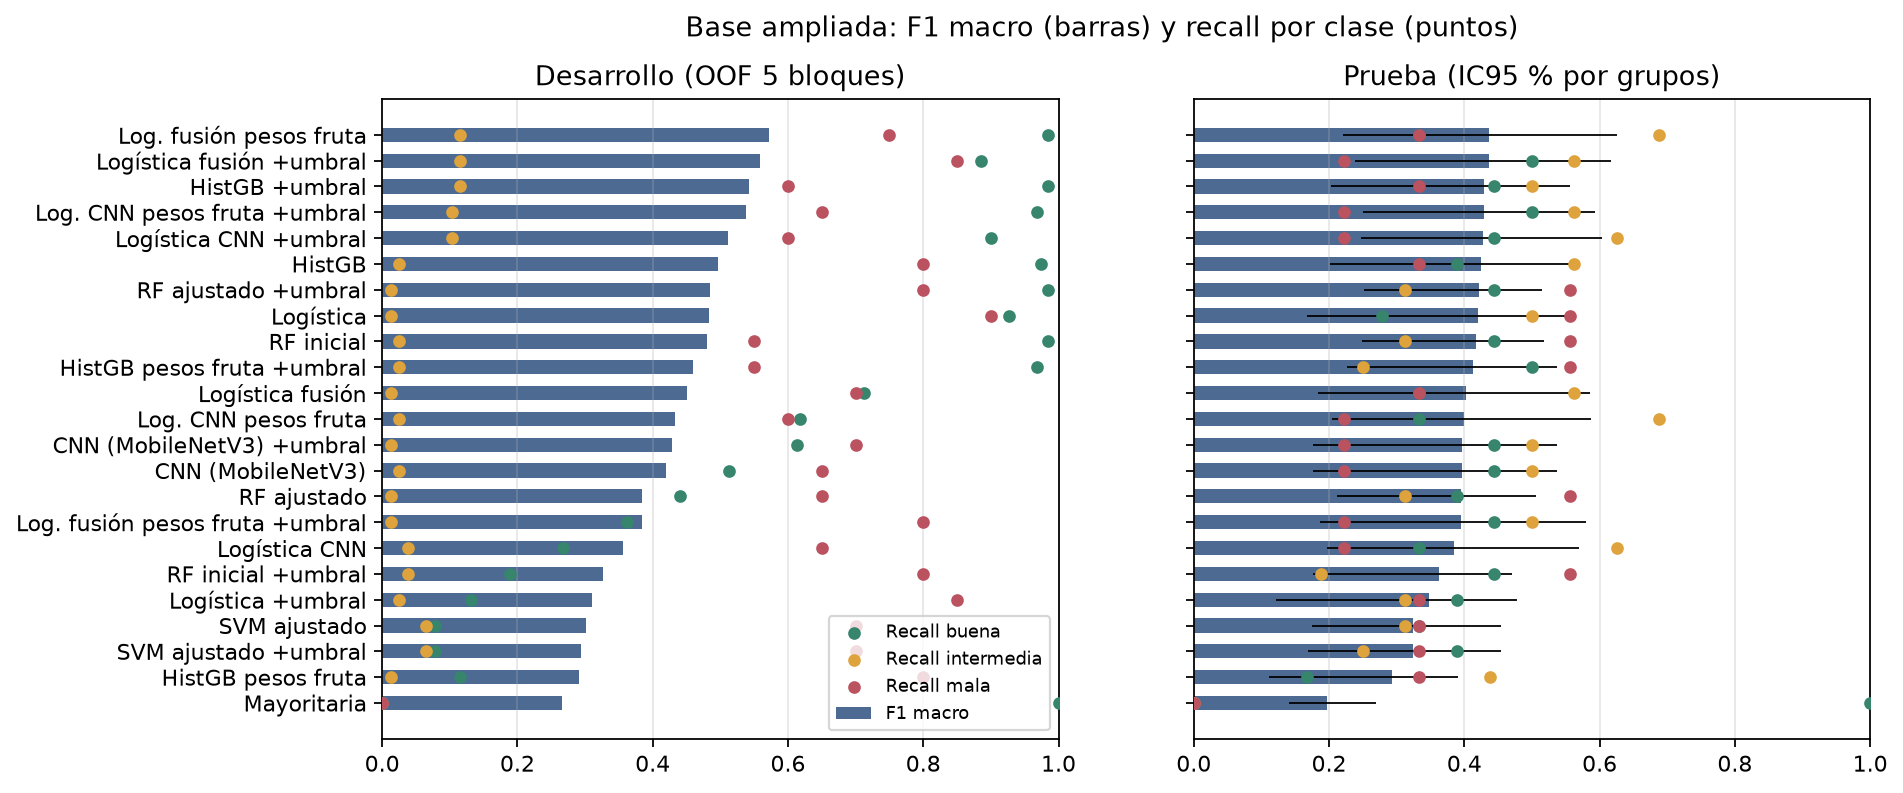

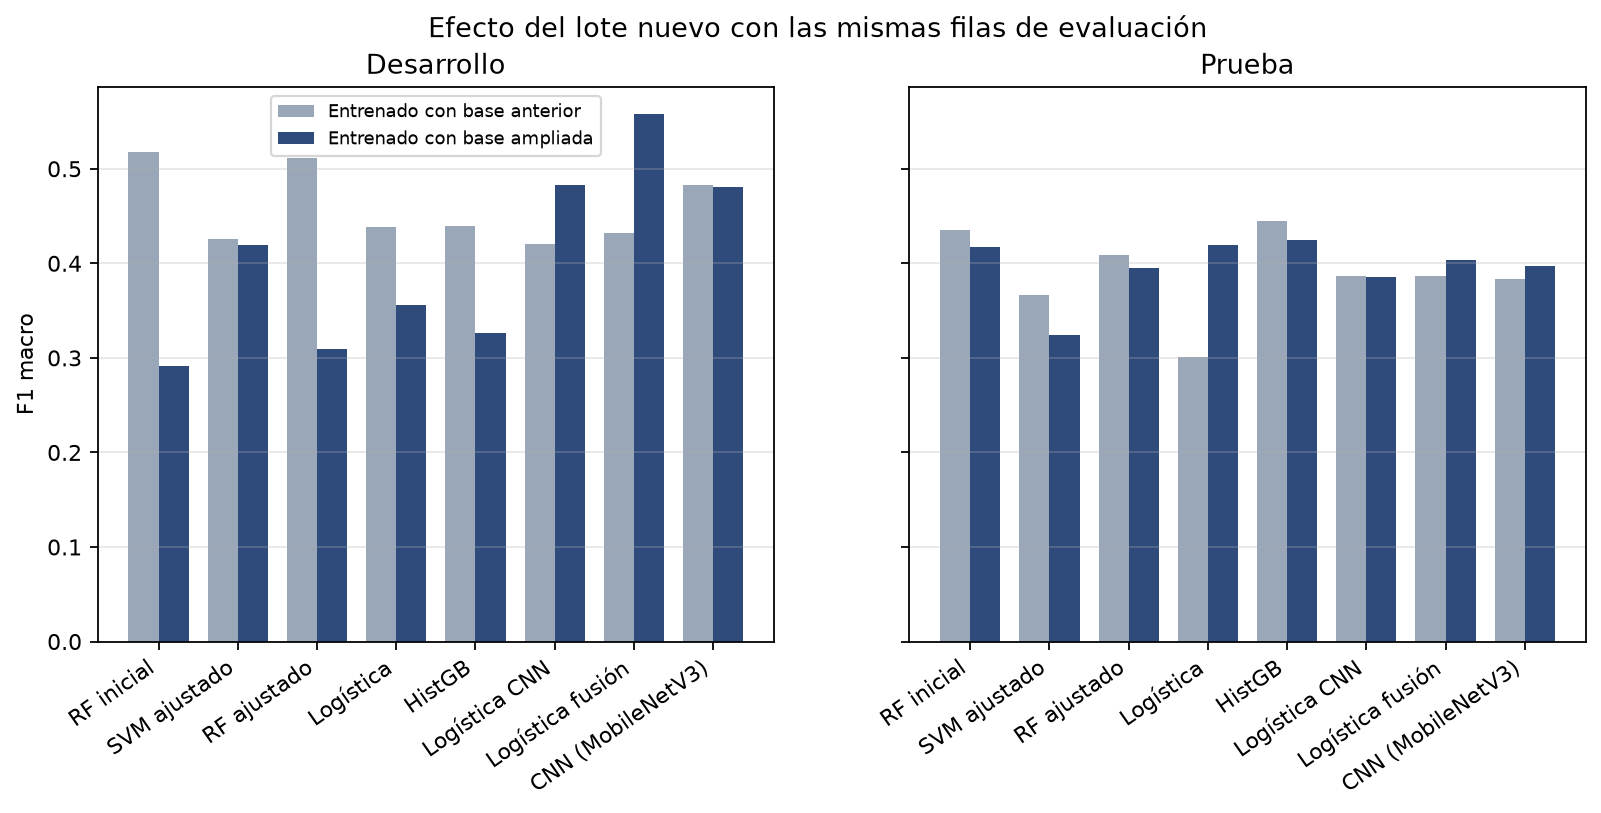

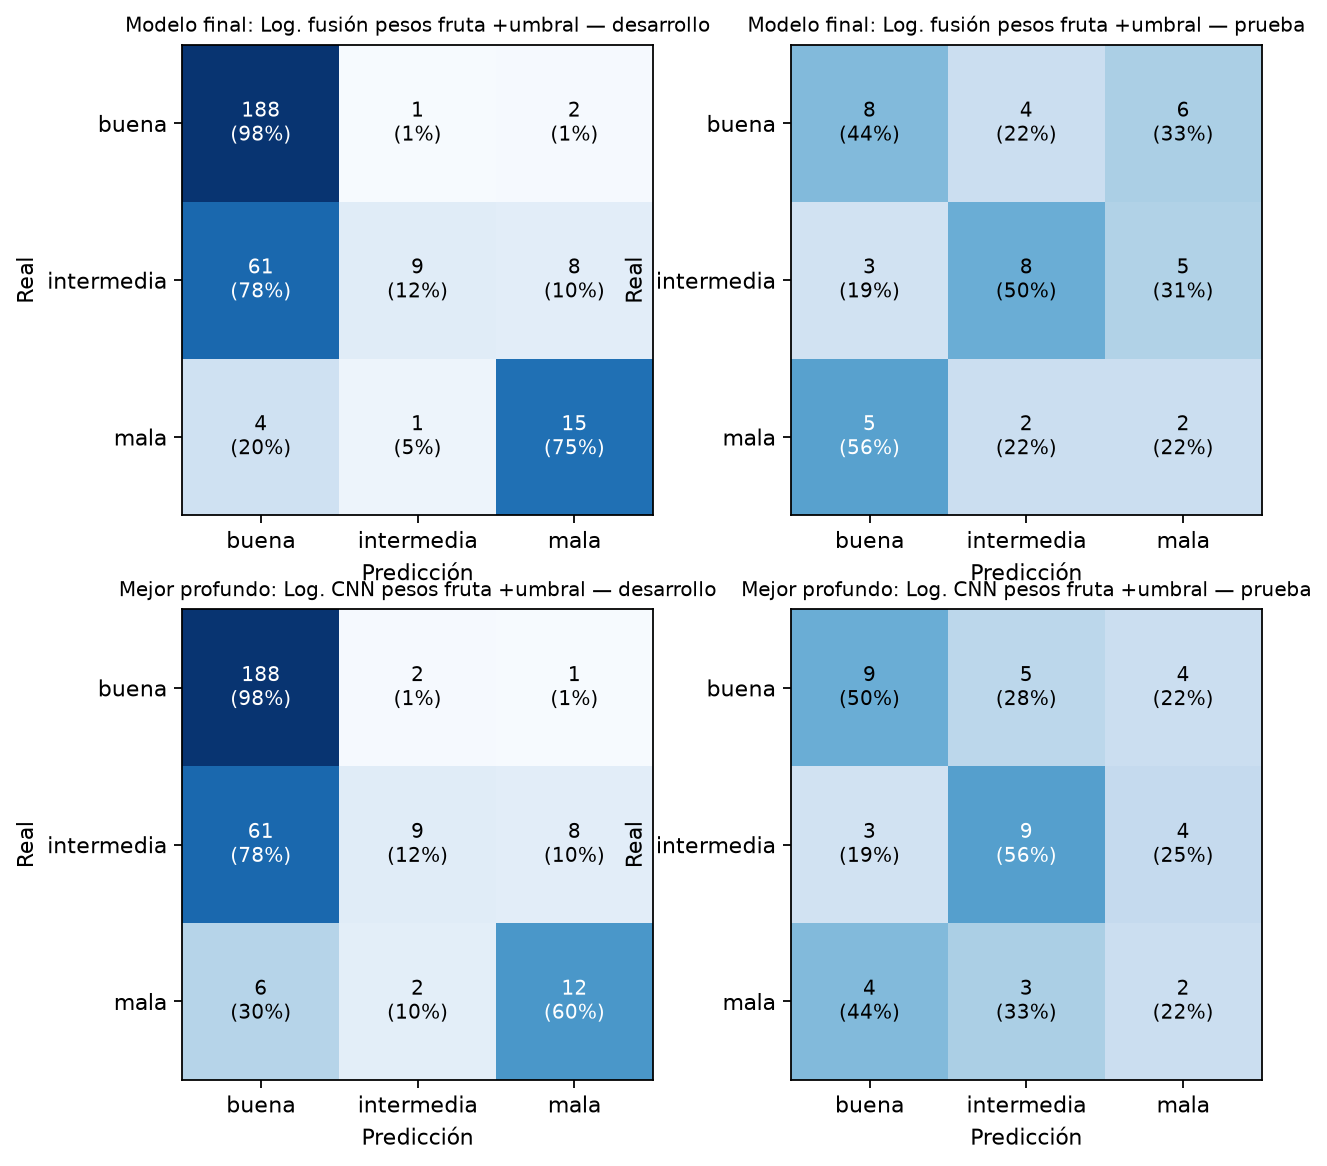

In [11]:
import subprocess
subprocess.run([sys.executable, str(PROYECTO / 'scripts/figuras_experimentos_v2.py')], check=True)
for nombre in ['v2_comparacion_modelos', 'v2_efecto_datos', 'v2_matrices_confusion']:
    display(Image(filename=str(PROYECTO / 'docs/figuras' / f'{nombre}.png')))

## 11. Sobreajuste: entrenamiento frente a validación

Se compara el F1 macro interno (validación agrupada dentro del entrenamiento) con el
externo. Una gran diferencia indica que la selección se ajustó a las campañas vistas.

In [12]:
aj = pd.read_csv(SALIDA / 'ajustes.csv')
aj = aj[(aj.condicion == 'ampliada') & (aj.pliegue != 'final')]
interno = aj.groupby('modelo')[['f1_interno', 'f1_interno_umbral']].mean()
externo = metricas.query("conjunto=='desarrollo' and condicion=='ampliada'").pivot(index='modelo', columns='variante', values='f1_macro')
display(interno.join(externo).rename(columns={'base': 'f1_externo', 'umbral': 'f1_externo_umbral'}).round(3))

,f1_interno,f1_interno_umbral,f1_externo,f1_externo_umbral
modelo,,,,
CNN_MobileNetV3_cabezal,0.555,0.545,0.480,0.460
HistGB_pesos_fruta,0.455,0.418,0.301,0.294
HistGradientBoosting,0.437,0.484,0.326,0.384
Logistica,0.341,0.410,0.356,0.384
Logistica_CNN,0.483,0.508,0.483,0.485
Logistica_CNN_pesos_fruta,0.496,0.503,0.538,0.542
Logistica_fusion,0.491,0.514,0.558,0.497
Logistica_fusion_pesos_fruta,0.455,0.515,0.512,0.572
RF_ajustado,0.393,0.558,0.310,0.429


## 12. Validación anidada sobre las 332 imágenes

Complemento de la prueba independiente: validación cruzada **anidada y agrupada** de 5 bloques
sobre todas las imágenes, repetida con tres semillas de partición (42, 7 y 2026). Cada imagen
recibe una predicción externa por repetición, como en la evaluación anterior de 3 bloques, pero
los hiperparámetros y los pesos de decisión se eligen siempre dentro del entrenamiento de cada
bloque. La desviación entre semillas mide la estabilidad. No se usa para elegir el modelo final.

In [13]:
from src.models.experimentos_base_ampliada import validacion_anidada_completa
meta = SALIDA / 'anidada_332.json'
if os.environ.get('FRUTAS_USAR_RESULTADOS') == '1' and meta.is_file():
    assert json.loads(meta.read_text(encoding='utf-8'))['sha_base'] == estado['sha_base']
    anidada = pd.read_csv(SALIDA / 'anidada_332_resumen.csv')
    print('Validación anidada guardada, verificada contra la base actual.')
else:
    anidada, _ = validacion_anidada_completa(PROYECTO)
cols_a = ['modelo', 'variante', 'f1_macro_media', 'f1_macro_desv', 'exactitud_media', 'f1_ponderado_media',
          'recall_buena_media', 'recall_intermedia_media', 'recall_mala_media']
display(anidada[cols_a].sort_values('f1_macro_media', ascending=False).round(3))
display(pd.read_csv(SALIDA / 'anidada_332_por_semilla.csv').pivot_table(index=['modelo', 'variante'], columns='semilla', values='f1_macro').round(3))

Validación anidada guardada, verificada contra la base actual.


,modelo,variante,f1_macro_media,f1_macro_desv,exactitud_media,f1_ponderado_media,recall_buena_media,recall_intermedia_media,recall_mala_media
7,CNN_MobileNetV3_cabezal,umbral,0.575,0.097,0.690,0.675,0.842,0.383,0.586
6,CNN_MobileNetV3_cabezal,base,0.558,0.076,0.673,0.658,0.832,0.344,0.586
9,Logistica_CNN,umbral,0.508,0.018,0.663,0.625,0.892,0.202,0.506
8,Logistica_CNN,base,0.472,0.021,0.616,0.587,0.815,0.174,0.621
13,Logistica_fusion_pesos_fruta,umbral,0.460,0.065,0.584,0.562,0.767,0.192,0.540
10,Logistica_CNN_pesos_fruta,base,0.450,0.013,0.568,0.556,0.726,0.206,0.609
12,Logistica_fusion_pesos_fruta,base,0.445,0.007,0.555,0.544,0.705,0.209,0.598
11,Logistica_CNN_pesos_fruta,umbral,0.436,0.055,0.549,0.537,0.703,0.202,0.563
2,RF_inicial,base,0.396,0.034,0.440,0.452,0.539,0.199,0.506
4,SVM_ajustado,base,0.330,0.053,0.408,0.416,0.509,0.230,0.253


semilla                                 7      42     2026
modelo                       variante                     
CNN_MobileNetV3_cabezal      base      0.646  0.506  0.522
                             umbral    0.687  0.521  0.516
Logistica_CNN                base      0.487  0.481  0.449
                             umbral    0.516  0.520  0.488
Logistica_CNN_pesos_fruta    base      0.462  0.451  0.436
                             umbral    0.475  0.373  0.459
Logistica_fusion_pesos_fruta base      0.441  0.453  0.441
                             umbral    0.531  0.404  0.446
RF_inicial                   base      0.433  0.389  0.367
                             umbral    0.242  0.374  0.353
Referencia_mayoritaria       base      0.258  0.258  0.258
                             umbral    0.258  0.258  0.258
SVM_ajustado                 base      0.385  0.328  0.279
                             umbral    0.214  0.202  0.368

## 13. Interpretación

La interpretación detallada y las limitaciones están en `docs/ajuste_y_cnn.md`
(sección de resultados), redactada a partir de estas tablas. El modelo final y su
variante quedan registrados en `experiments/checkpoints/experimentos_v2/manifiesto.json`,
que usa la interfaz (`python -m src.main`).

In [14]:
print(json.dumps(manifiesto, ensure_ascii=False, indent=2))

{
  "sha_base": "bf1bbae08894ae929e36ed7926968cd74dbb0a01a50c3fc05c3aa9a2042137c3",
  "modelo_final": {
    "modelo": "Logistica_fusion_pesos_fruta",
    "variante": "umbral"
  },
  "modelos": {
    "CNN_MobileNetV3_cabezal": {
      "archivo": "experiments/checkpoints/experimentos_v2/cnn_mobilenetv3_cabezal.pt",
      "variante": "base",
      "f1_macro_desarrollo": 0.4802,
      "f1_macro_prueba": 0.3967
    },
    "HistGB_pesos_fruta": {
      "archivo": "experiments/checkpoints/experimentos_v2/histgb_pesos_fruta.joblib",
      "variante": "base",
      "f1_macro_desarrollo": 0.3007,
      "f1_macro_prueba": 0.2924
    },
    "HistGradientBoosting": {
      "archivo": "experiments/checkpoints/experimentos_v2/histgradientboosting.joblib",
      "variante": "umbral",
      "f1_macro_desarrollo": 0.3835,
      "f1_macro_prueba": 0.4289
    },
    "Logistica": {
      "archivo": "experiments/checkpoints/experimentos_v2/logistica.joblib",
      "variante": "umbral",
      "f1_macro_desar